In [1]:
!pip install setuptools
!pip install cython
!pip install matplotlib
!python --version

Python 3.14.4


In [2]:
# requires both cython and setuptools?
%load_ext cython

In [3]:
import math
def primes_count(from_n, to_m):
    assert(2 <= from_n and from_n <= to_m)
    sieve = [1] * (math.isqrt(to_m) + 1)
    sieve[0] = 0
    sieve[1] = 0
    for i in range(2, math.isqrt(len(sieve))):
        if not sieve[i]:
            continue;
        #j = 2 * i
        #while j < len(sieve):
        for j in range(2 * i, len(sieve), i):
            sieve[j] = 0
            #j += i
    primes = [ i for i in range(len(sieve)) if sieve[i] ]
    #print(primes)

    larger_primes = []
    for i in range(from_n, to_m + 1):
        f = i
        for p in primes:
            if 0 == i % p:
                f = p
                break;
        if f == i:
            larger_primes.append(i)
    #print(larger_primes)
    return len(larger_primes)

print(primes_count(2, 1000))
print(primes_count(907, 997))
print(primes_count(10**10-999, 10**10))

168
14
41


In [4]:
%%cython

import math
def primes_count_cy0(from_n, to_m):
    assert(2 <= from_n and from_n <= to_m)
    sieve = [1] * (math.isqrt(to_m) + 1)
    sieve[0] = 0
    sieve[1] = 0
    for i in range(2, math.isqrt(len(sieve))):
        if not sieve[i]:
            continue;
        #j = 2 * i
        #while j < len(sieve):
        for j in range(2 * i, len(sieve), i):
            sieve[j] = 0
            #j += i
    primes = [ i for i in range(len(sieve)) if sieve[i] ]
    #print(primes)

    larger_primes = []
    for i in range(from_n, to_m + 1):
        f = i
        for p in primes:
            if 0 == i % p:
                f = p
                break;
        if f == i:
            larger_primes.append(i)
    #print(larger_primes)
    return len(larger_primes)

print(primes_count_cy0(2, 1000))
print(primes_count_cy0(907, 997))
print(primes_count_cy0(10**10-999, 10**10))

168
14
41


In [5]:
%%cython --compile-args=-O3

# cython: boundscheck=False, wraparound=False, cdivision=True
import cython
import math

def primes_count_cy1(from_n: cython.ulonglong, to_m: cython.ulonglong):
    i: cython.ulonglong
    j: cython.ulonglong
    assert(2 <= from_n and from_n <= to_m)
    sieve: list[cython.uchar] = [1] * (math.isqrt(to_m) + 1)
    sieve[0] = 0
    sieve[1] = 0
    for i in range(2, math.isqrt(len(sieve))):
        if not sieve[i]:
            continue;
        #for j in range(2 * i, len(sieve), i):
        j = 2 * i
        while j < len(sieve):
            sieve[j] = 0
            j += i
    primes: list[cython.ulonglong] = [ i for i in range(len(sieve)) if sieve[i] ]
    #print(primes)

    larger_primes: list[ulonglong] = []
    f: cython.ulonglong
    p: cython.ulonglong
    for i in range(from_n, to_m + 1):
        f = i
        for p in primes:
            if 0 == i % p:
                f = p
                break;
        if f == i:
            larger_primes.append(i)
    #print(larger_primes)
    return len(larger_primes)

print(primes_count_cy1(2, 1000))
print(primes_count_cy1(907, 997))
print(primes_count_cy1(10**10-999, 10**10))

168
14
41


In [6]:
%%cython

# distutils: language=c++
# distutils: extra_compile_args = -O3 -std=c++20 -funroll-loops
# cython: language_level=3
import cython
from libcpp.vector cimport vector
import math

@cython.cdivision(True)
cdef unsigned long long primes_count_impl(unsigned long long from_n, unsigned long long to_m):
    cdef unsigned long long i, j, f, p
    cdef vector[unsigned char] sieve
    
    assert(2 <= from_n and from_n <= to_m)
    sieve.reserve(math.isqrt(to_m) + 1)
    sieve.assign(math.isqrt(to_m) + 1, 1)

    sieve[0] = 0
    sieve[1] = 0
    cdef int primes_found = 0
    for i in range(2, math.isqrt(sieve.size())):
        if not sieve[i]:
            continue;
        primes_found += 1
        #for j in range(2 * i, sieve.size(), i): # Cython does not optimize range() as a C loop with non-constant arguments
        j = 2 * i
        while j < sieve.size():
            sieve[j] = 0
            j += i

    cdef vector[unsigned long long] primes
    primes.reserve(primes_found)
    for i in range(sieve.size()):
        if sieve[i]:
            primes.push_back(i)
    #print(primes)

    cdef vector[unsigned long long] larger_primes
    larger_primes.reserve(primes.size()) # gross estimate to minimize future reallocations
    for i in range(from_n, to_m + 1):
        f = i
        for p in primes:
            if 0 == i % p:
                f = p
                break;
        if f == i:
            larger_primes.push_back(i)
    #print(larger_primes)
    return larger_primes.size()

def primes_count_cy2(from_n: cython.ulonglong, to_m: cython.ulonglong):
    return primes_count_impl(from_n, to_m)

print()
print(primes_count_cy2(2, 1000))
print(primes_count_cy2(907, 997))
print(primes_count_cy2(10**10-999, 10**10))


168
14
41


In [7]:
from timeit import timeit
print('Pure Python primes_count')
for k in range(4, 13):
    t = timeit(lambda: primes_count(10**k - 1000, 10**k), number=10)
    print(f'primes_count(10**{k} - 1000, 10**{k}) takes {t} seconds')

print()
print('Cython primes_count_cy0 as is')
for k in range(4, 13):
    t = timeit(lambda: primes_count_cy0(10**k - 1000, 10**k), number=10)
    print(f'primes_count_cy0(10**{k} - 1000, 10**{k}) takes {t} seconds')

print()
print('Cython primes_count_cy1 (annotated)')
for k in range(4, 13):
    t = timeit(lambda: primes_count_cy1(10**k - 1000, 10**k), number=10)
    print(f'primes_count_cy1(10**{k} - 1000, 10**{k}) takes {t} seconds')

print()
print('Cython primes_count_cy2 (annotated, uses cdef, uses cython arrays)')
for k in range(4, 13):
    t = timeit(lambda: primes_count_cy2(10**k - 1000, 10**k), number=10)
    print(f'primes_count_cy2(10**{k} - 1000, 10**{k}) takes {t} seconds')

Pure Python primes_count
primes_count(10**4 - 1000, 10**4) takes 0.0013944170000002032 seconds
primes_count(10**5 - 1000, 10**5) takes 0.0021702500000060354 seconds
primes_count(10**6 - 1000, 10**6) takes 0.004613541999987092 seconds
primes_count(10**7 - 1000, 10**7) takes 0.010924999999986085 seconds
primes_count(10**8 - 1000, 10**8) takes 0.022371999999990066 seconds
primes_count(10**9 - 1000, 10**9) takes 0.05545241699999792 seconds
primes_count(10**10 - 1000, 10**10) takes 0.1557305000000042 seconds
primes_count(10**11 - 1000, 10**11) takes 0.42847512599999504 seconds
primes_count(10**12 - 1000, 10**12) takes 1.2111691260000157 seconds

Cython primes_count_cy0 as is
primes_count_cy0(10**4 - 1000, 10**4) takes 0.0006740830000069309 seconds
primes_count_cy0(10**5 - 1000, 10**5) takes 0.0010238749999871288 seconds
primes_count_cy0(10**6 - 1000, 10**6) takes 0.0024740419999886853 seconds
primes_count_cy0(10**7 - 1000, 10**7) takes 0.006278750000006994 seconds
primes_count_cy0(10**8 - 1

Milliseconds per call
                   range            Python      Cython as is  Cython annotated       Cython cdef
   [10**4 - 1000, 10**4]             0.149             0.076             0.017             0.006
   [10**5 - 1000, 10**5]             0.233             0.106             0.019             0.008
   [10**6 - 1000, 10**6]             0.458             0.257             0.034             0.014
   [10**7 - 1000, 10**7]             0.897             0.642             0.068             0.029
   [10**8 - 1000, 10**8]             2.137             1.664             0.174             0.071
   [10**9 - 1000, 10**9]             5.225             4.455             0.515             0.175
 [10**10 - 1000, 10**10]            15.365            14.509             1.400             0.493
 [10**11 - 1000, 10**11]            42.362            42.227             4.082             1.429
 [10**12 - 1000, 10**12]           119.997           122.972            11.892             3.965

Speedup

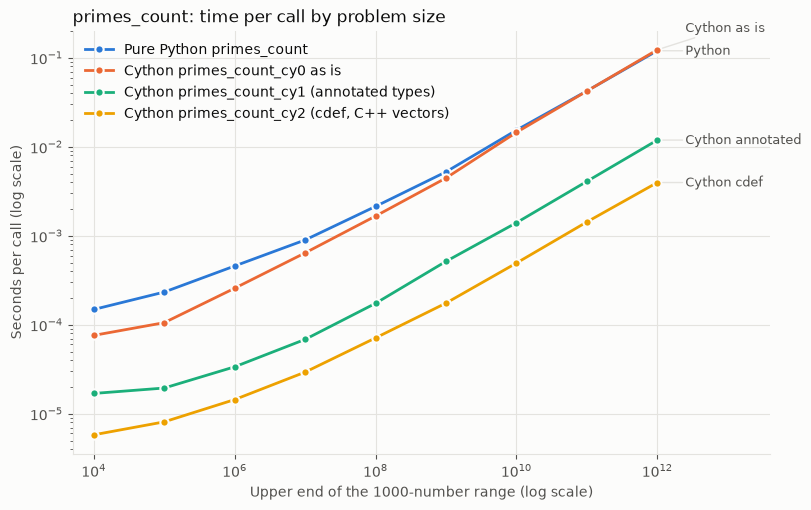

In [8]:
# Time per call of all four primes_count versions for growing problem sizes:
# a table in the console, then a log-log plot
from timeit import timeit
import matplotlib.pyplot as plt

candidates = [  # (legend label, short label, function); colors follow this order
    ('Pure Python primes_count', 'Python', primes_count),
    ('Cython primes_count_cy0 as is', 'Cython as is', primes_count_cy0),
    ('Cython primes_count_cy1 (annotated types)', 'Cython annotated', primes_count_cy1),
    ('Cython primes_count_cy2 (cdef, C++ vectors)', 'Cython cdef', primes_count_cy2),
]
exponents = range(4, 13)  # each call counts primes in [10**k - 1000, 10**k]
number = 10  # calls per measurement

seconds_per_call = {}
for label, short, function in candidates:
    seconds_per_call[short] = [timeit(lambda: function(10**k - 1000, 10**k), number=number) / number
                               for k in exponents]

print('Milliseconds per call')
print(f'{"range":>24s}' + ''.join(f'{short:>18s}' for _, short, _ in candidates))
for i, k in enumerate(exponents):
    print(f'{f"[10**{k} - 1000, 10**{k}]":>24s}'
          + ''.join(f'{seconds_per_call[short][i] * 1e3:18.3f}' for _, short, _ in candidates))

for exp in (0, -1):
    python_time = seconds_per_call['Python'][exp]
    print(f'\nSpeedup over pure Python at 10**{exponents[exp]}: '
          + ', '.join(f'{short} x{python_time / seconds_per_call[short][exp]:.2f}' for _, short, _ in candidates[1:]))

# Categorical slots 1-4 of the reference palette, validated for adjacent lines on a light surface
colors = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']
surface, text_primary, text_secondary, grid = '#fcfcfb', '#0b0b0b', '#52514e', '#e4e3df'

sizes = [10**k for k in exponents]
fig, ax = plt.subplots(figsize=(9, 5.5), facecolor=surface)
ax.set_facecolor(surface)
for (label, short, _), color in zip(candidates, colors):
    ax.plot(sizes, seconds_per_call[short], color=color, linewidth=2, marker='o', markersize=6,
            markeredgecolor=surface, markeredgewidth=1.5, label=label)

# Direct labels at the line ends, nudged apart where lines end close together
label_y = []
for value, short in sorted((seconds_per_call[short][-1], short) for _, short, _ in candidates):
    y = max(value, label_y[-1] * 1.8) if label_y else value
    label_y.append(y)
    ax.annotate(short, xy=(sizes[-1], value), xytext=(sizes[-1] * 2.5, y), color=text_secondary, fontsize=9,
                va='center', arrowprops=dict(arrowstyle='-', color=grid, linewidth=1, shrinkA=0, shrinkB=4))

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(sizes[0] / 2, sizes[-1] * 40)
ax.set_xlabel('Upper end of the 1000-number range (log scale)', color=text_secondary)
ax.set_ylabel('Seconds per call (log scale)', color=text_secondary)
ax.set_title('primes_count: time per call by problem size', color=text_primary, loc='left')
ax.grid(True, which='major', color=grid, linewidth=0.8)
ax.tick_params(colors=text_secondary, which='both')
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
for side in ('left', 'bottom'):
    ax.spines[side].set_color(grid)
ax.legend(loc='upper left', frameon=False, labelcolor=text_primary)
plt.show()